In [21]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


In [3]:
daten = load_breast_cancer(as_frame=True)

In [5]:
X,y = daten.data, daten.target

In [6]:
print(X.shape, y.shape)

(569, 30) (569,)


In [7]:
X

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,0.07871,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,0.05667,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,0.05999,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,0.09744,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,0.05883,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [8]:
y

0      0
1      0
2      0
3      0
4      0
      ..
564    0
565    0
566    0
567    0
568    1
Name: target, Length: 569, dtype: int64

In [9]:
y.value_counts().rename({1: "gut", 0: "böse"})

target
gut     357
böse    212
Name: count, dtype: int64

# Das Problem

In [19]:
accs = []

for seed in range(30):
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, random_state=seed, test_size=0.2)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(5))
    model.fit(X_tr, y_tr)
    accs.append(accuracy_score(y_te, model.predict(X_te)))

In [20]:
accs

[0.956140350877193,
 0.956140350877193,
 0.9736842105263158,
 0.9473684210526315,
 0.9649122807017544,
 0.9649122807017544,
 0.956140350877193,
 0.956140350877193,
 0.9824561403508771,
 0.9649122807017544,
 0.9912280701754386,
 0.9736842105263158,
 0.956140350877193,
 0.9736842105263158,
 0.956140350877193,
 0.956140350877193,
 0.9912280701754386,
 0.956140350877193,
 0.9649122807017544,
 0.9385964912280702,
 0.956140350877193,
 0.9824561403508771,
 0.9736842105263158,
 0.9912280701754386,
 0.9649122807017544,
 0.956140350877193,
 0.9736842105263158,
 0.9649122807017544,
 0.9912280701754386,
 0.9649122807017544]

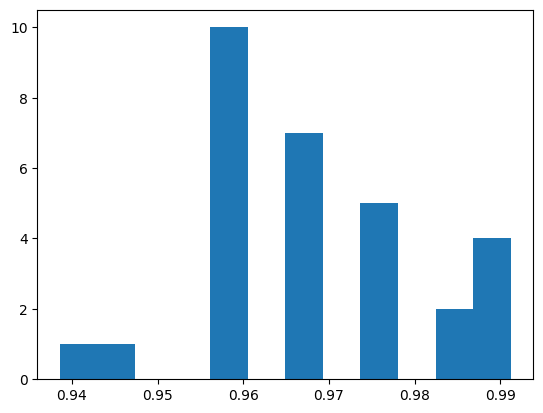

In [23]:
plt.hist(accs, bins=12)
plt.show()

In [24]:
print(f"min: {min(accs)} max: {max(accs)} spannweite: {max(accs) - min(accs)}")

min: 0.9385964912280702 max: 0.9912280701754386 spannweite: 0.05263157894736836


# Die Lösung
## Train / Validation / Test split

In [25]:
X_rest, X_te, y_rest, y_te = train_test_split(X, y, random_state=42, test_size=0.2)
X_tr, X_va, y_tr, y_va = train_test_split(X_rest, y_rest, random_state=42, test_size=0.2)

print(X_tr.shape, y_tr.shape, y_va.shape, y_te.shape)

(364, 30) (364,) (91,) (114,)


In [34]:
result = {}

for k in range(1,52, 2):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(k))
    model.fit(X_tr, y_tr)
    result[k] = (accuracy_score(y_va, model.predict(X_va)), model)

In [37]:
best_model_index = max(result, key=lambda k: result.get(k)[0])
best_model = result[best_model_index][1]

In [43]:
acc = accuracy_score(y_te, best_model.predict(X_te))
print(f"best k: {best_model_index} best accuracy validation: {result[best_model_index][0]} accuracy test: {acc}")

best k: 3 best accuracy validation: 0.978021978021978 accuracy test: 0.9473684210526315
